# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [4]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:

# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [12]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ 
A)  Dataset: users
   1.- city: 469 valores nulos (11.73%).
   
Acción recomendada: Investigar e imputar.

Justificación: El porcentaje de nulos es moderado (entre 5% y 30%), por lo que conviene revisar si es posible recuperar la información o imputarla utilizando otras variables relacionadas.

   2.- churn_date: 3,534 valores nulos (88.35%).
   
Acción recomendada: Mantener los nulos y analizar el significado de la variable antes de eliminarla.

Justificación: En telecomunicaciones, una fecha de cancelación suele estar vacía para clientes activos, por lo que estos nulos probablemente representan información válida y no datos faltantes.

B)   Dataset: usage

   1.- date: 50 valores nulos (0.13%).
   
Acción recomendada: Imputar o eliminar los registros afectados.

Justificación: La proporción es muy baja (<5%), por lo que su impacto en el análisis es mínimo.

   2.-duration: 22,076 valores nulos (55.19%).

Acción recomendada: Investigar antes de imputar o eliminar.

Justificación: El porcentaje es elevado; es probable que la columna solo aplique a determinados tipos de uso (por ejemplo, llamadas) y que los nulos tengan un significado operativo.

   3.- length: 17,896 valores nulos (44.74%).
   
Acción recomendada: Investigar antes de imputar o eliminar.

Justificación: La proporción es alta y podría estar relacionada con otro tipo de servicio (por ejemplo, mensajes), por lo que los nulos podrían ser esperados y no errores de captura.

Conclusión

La mayoría de las columnas no presentan valores faltantes. Los nulos en city requieren revisión e imputación potencial, mientras que churn_date probablemente representa clientes activos y no debe eliminarse automáticamente. En usage, las columnas duration y length necesitan un análisis adicional porque los nulos podrían estar asociados al tipo de registro y formar parte del comportamiento normal de los datos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


-
 
La columna `user_id` ... corresponde a un identificador único de cliente. Los valores van de 10000 a 13999 y no se observan anomalías aparentes. Al ser una clave identificadora, no requiere análisis estadístico adicional.
- La columna `age` ...presenta un valor mínimo de -999, lo cual es imposible para una edad y sugiere la presencia de un sentinel utilizado para representar datos faltantes o errores de captura. Además, la desviación estándar es muy alta (123.23 años), probablemente debido a este valor atípico. Se recomienda investigar y reemplazar los registros con edad = -999 por valores nulos (NaN) antes de continuar con el análisis.



In [14]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...corresponden a identificadores de registros y usuarios. Sus valores se encuentran dentro de rangos consistentes y no presentan anomalías evidentes. Al ser variables de identificación, no requieren análisis estadístico de negocio.
- 
- La columna duration, presenta valores entre 0 y 120 minutos. Se observa que existen registros con duración igual a 0, los cuales podrían corresponder a llamadas no completadas o registros especiales. Se recomienda validar su significado antes de eliminarlos.

La columna length, presenta valores entre 0 y 1490 caracteres. El valor máximo es considerablemente superior a la mediana (50) y al tercer cuartil (64), lo que sugiere la existencia de mensajes excepcionalmente largos o posibles valores atípicos. Se recomienda revisar estos casos durante el análisis de outliers.

In [15]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
     print(users[col].value_counts(dropna=False))


Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` contiene ciudades válidas como Bogotá, CDMX, Medellín, GDL, Cali y MTY; sin embargo, presenta 469 valores nulos (11.73%) y 96 registros con el valor "?", el cual parece ser un sentinel utilizado para representar información desconocida. Se recomienda reemplazar "?" por valores nulos (NaN) y posteriormente evaluar una estrategia de imputación o mantenerlos como faltantes.
- 
- La columna `plan` contiene únicamente las categorías esperadas (Basico y Premium) y no presenta valores faltantes ni categorías inconsistentes. No se identifican sentinels ni problemas de calidad en esta variable.

In [16]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...contiene únicamente dos categorías: text y call, no se observan valores faltantes, categorías desconocidas ni sentinels. La variable parece consistente y representa correctamente los dos tipos de uso del servicio analizados en el dataset.


---
✍️ 
   A) Columna age:
   
Se identificó el valor -999 como un sentinel, ya que una edad negativa no es posible en la realidad.

Acción recomendada: Reemplazar los valores -999 por NaN para tratarlos posteriormente mediante imputación o exclusión según el análisis.

   B) Columna city:
   
Se identificó el valor "?" como un sentinel utilizado para representar información desconocida o faltante.

Acción recomendada: Reemplazar "?" por NaN y posteriormente evaluar si conviene imputar la ciudad o mantener el valor como faltante.

   C) Columna plan:
   
No se encontraron valores inválidos ni categorías inesperadas. Solo aparecen los planes Basico y Premium.

Acción recomendada: No realizar cambios.

   D)Columna type:
   
No se encontraron valores inválidos ni sentinels. Las categorías call y text son consistentes con la naturaleza del negocio.

Acción recomendada: No realizar cambios.

   Conclusión

Los principales problemas de calidad de datos corresponden a los sentinels -999 en age y "?" en city. Ambos deben convertirse a valores nulos (NaN) antes de continuar con el análisis para evitar sesgos en las métricas y segmentaciones posteriores.





### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
print(users['reg_date'].dtype)

datetime64[ns]


In [18]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')
print(usage['date'].dtype)

datetime64[ns]


In [19]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, Los años 2022, 2023 y 2024 son notablemente estables, lo que sugiere una adquisición muy uniforme, 2026 tiene solo 40 registros frente a los años anteriores, esto no es una caída real de registros, sino que 2026 está incompleto, así que esos 40 usuarios son los registrados hasta la fecha actual.

In [20]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date`, ...todos los registros válidos corresponden al año 2024, lo cual es consistente con el período de análisis definido para el proyecto. No se identifican años futuros ni fechas fuera de rango.

   A) Columna reg_date:

   1.- Se identificaron 40 registros correspondientes al año 2026, mientras que el análisis está definido hasta el año 2024.

   2.- Acción recomendada: Investigar estos registros para confirmar si se trata de errores de captura. Si no es posible validar la fecha correcta, se recomienda corregirlos o excluirlos del análisis para evitar conclusiones incorrectas sobre el comportamiento de los clientes.

   B)Columna date:

   1.- Todos los registros válidos corresponden al año 2024, por lo que no se identifican fechas fuera de rango ni años futuros.

   2.- Acción recomendada: No se requieren correcciones. Solo revisar los registros con valores nulos (NaT) para determinar si corresponden a fechas faltantes o errores de formato.

   Conclusion:

   Se detectaron fechas fuera de rango únicamente en la columna reg_date, donde aparecen registros del año 2026. Estas fechas deben investigarse y corregirse antes de continuar con el análisis. La columna date presenta años consistentes con el período de estudio y no requiere ajustes adicionales.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
age_mediana =  users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:


# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))



Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [23]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT


# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False).sort_index())


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())

type
call        0
text    22076
Name: duration, dtype: int64

In [25]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().sum())

type
call    17896
text        0
Name: length, dtype: int64

   A) Columna duration

   1.- Se observó que los 22,076 valores nulos de duration aparecen exclusivamente en registros de tipo text.
   2.- Los registros de tipo call no presentan valores nulos en esta columna.

   Conclusion: Los nulos dependen directamente de la variable type, ya que los mensajes de texto no tienen duración de llamada.

   Accion: Mantener los valores nulos, ya que representan información no aplicable y no errores de captura.

   B) Columna length

   1.- Se observó que los 17,896 valores nulos de length aparecen exclusivamente en registros de tipo call.

   2.- Los registros de tipo text no presentan valores nulos en esta columna.

   Conclusion: Los nulos dependen directamente de la variable type, ya que las llamadas no tienen longitud de mensaje.

   Accion: Mantener los valores nulos, ya que representan información no aplicable y no errores de captura.

   Conclusion:

   Los valores nulos en duration y length no son errores ni información faltante aleatoria. Están asociados al tipo de servicio registrado (call o text), por lo que corresponden a datos no aplicables para determinadas observaciones. Se recomienda conservar estos nulos y no imputarlos para preservar el significado original de los datos.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [30]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

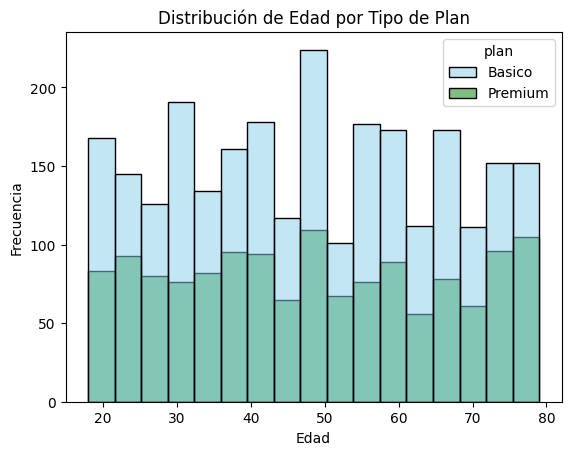

In [31]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'])
plt.title('Distribución de Edad por Tipo de Plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- La Distribución no sigue una campana normal. Hay un pico pronunciado a los 50 años impulsado por el plan Básico, y valles en los 40 y 50s (64 y 100 respectivamente). Las edades extremas (20 y 80) tienen niveles similares entre sí.
- 
-   Insights clave:

    1.- El plan Básico domina y tiene un pico atípico a los 50 años. Con ~225 usuarios, ese grupo representa claramente una anomalía. Podría haber una campaña de adquisición, una cohorte generacional, o un evento externo que concentró usuarios de esa edad en ese plan.

    2.- El plan Premium es notablemente estable. A diferencia del Básico, Premium mantiene una frecuencia casi plana entre 65 y 110 usuarios en todos los grupos etarios. Esto sugiere que los usuarios Premium no tienen un perfil etario dominante, o que hay un "techo" de conversión al plan pagado independiente de la edad.

    3.- La distribución total no es normal (gaussiana). Si fuera una distribución sana de usuarios por edad, esperaríamos una campana centrada en algún rango. Aquí hay irregularidades claras: el valle pronunciado a los 40 y los 50 (básico bajo) y el spike a los 50 rompen cualquier patrón suave.

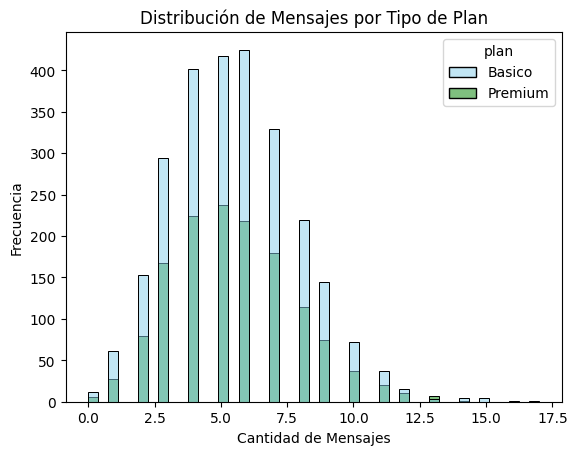

In [32]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de Mensajes por Tipo de Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')

plt.show()

💡Insights: 
La mayor parte de los usuarios envía entre 3 y 8 mensajes, concentrándose el pico de la distribución alrededor de 5 y 6 mensajes. Los usuarios de los planes Básico y Premium presentan patrones muy similares, ya que las distribuciones se superponen ampliamente y no se observa una diferencia clara en el volumen de mensajes enviados según el plan. La distribución es sesgada a la derecha (asimetría positiva), ya que la mayoría de los usuarios se concentra en cantidades bajas o medias de mensajes, mientras que un grupo reducido registra cantidades más altas (13 a 17 mensajes), formando una cola hacia la derecha. El tipo de plan no parece influir significativamente en la cantidad de mensajes enviados. Esto podría indicar que el servicio de mensajería no es un factor diferenciador importante entre los clientes de los planes Básico y Premium, por lo que la empresa podría enfocarse en otras variables de consumo (como minutos de llamadas o datos móviles) para diseñar estrategias de segmentación o mejora de planes.

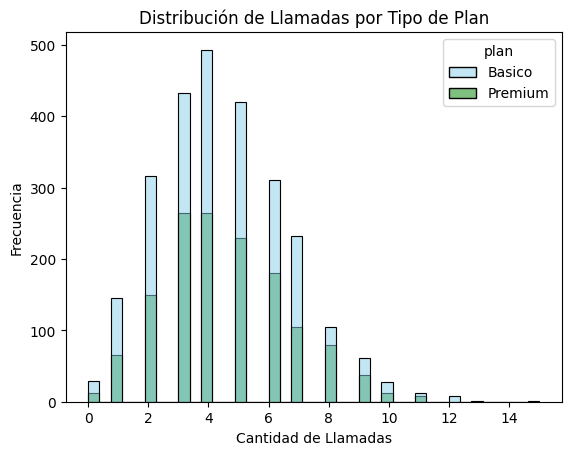

In [33]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de Llamadas por Tipo de Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Frecuencia')

plt.show()

💡Insights: 

- La distribución sigue un patrón tipo Poisson o binomial negativa: mayoría de usuarios con valores bajos-medios (3–5), cola larga hacia la derecha. El eje X podría representar sesiones, compras, interacciones u otro evento recurrente. Los usuarios Premium muestran valores más altos de forma consistente, lo que sugiere una correlación entre mayor actividad o uso y la adopción del plan pagado.

- Insights:

   1.- Distribución sesgada a la derecha. La masa de usuarios se concentra entre los valores 3 y 6, con un pico en 4. A partir de ahí, la frecuencia cae progresivamente formando una cola larga. Esto es típico de métricas de comportamiento como sesiones, compras o eventos por usuario.

   2.- El plan Básico domina solo en valores muy bajos. Conforme sube el valor en X, el plan Premium va ganando participación hasta ser casi la totalidad de los usuarios en la cola derecha. Esto indica que los usuarios de mayor actividad o uso tienden a tener plan Premium.

   3.- La zona 2–6 es crítica para el negocio. Ahí está el mayor volumen total de usuarios y la mayor mezcla entre ambos planes. Es el segmento con más potencial de conversión: usuarios ya activos que aún están en Básico.

   4.- La cola derecha 8–14 es casi exclusivamente Premium. Pocos usuarios llegan ahí, pero son casi todos de pago. Esto podría indicar que el producto Premium desbloquea comportamientos de mayor uso, o que los usuarios más comprometidos naturalmente migran a Premium.

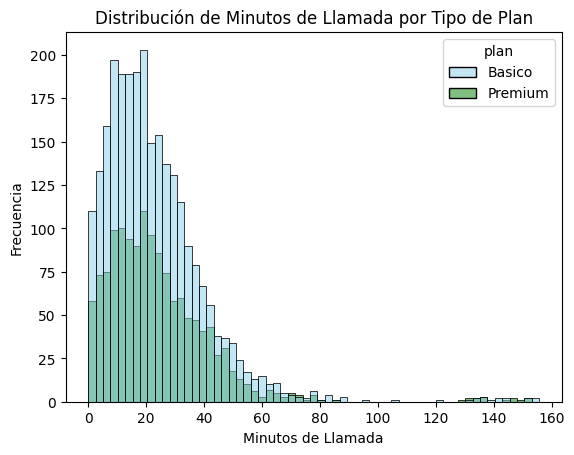

In [34]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de Minutos de Llamada por Tipo de Plan')
plt.xlabel('Minutos de Llamada')
plt.ylabel('Frecuencia')

plt.show()

💡Insights: 
- Insight:

- 1.- Ambos planes siguen la misma forma de distribución. Tanto Básico como Premium tienen una distribución sesgada a la derecha con pico entre 10–25 minutos. No hay una diferencia estructural en el comportamiento de llamadas entre planes.

- 2.- Básico tiene mayor volumen absoluto en toda la distribución. La barra azul supera consistentemente a la verde en todos los rangos. Esto simplemente refleja que hay más usuarios Básico que Premium en el dataset, no necesariamente que llamen más.

- 3.- La forma de Premium imita a Básico casi perfectamente. Las curvas son casi paralelas, lo que sugiere que el tipo de plan no cambia el patrón de uso telefónico. Un usuario Premium no llama ni más ni menos tiempo que uno Básico en términos proporcionales.

- 

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

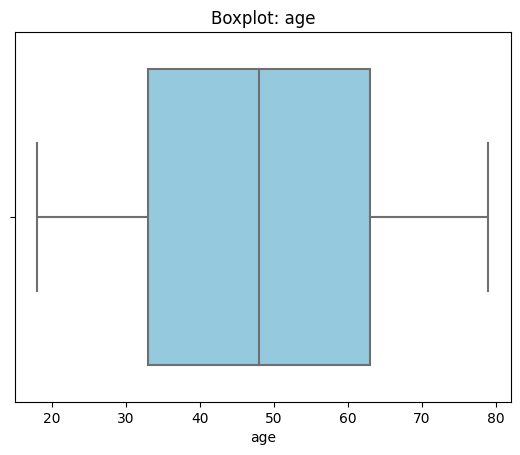

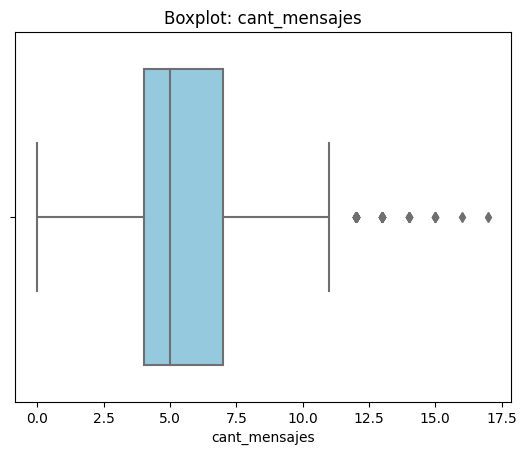

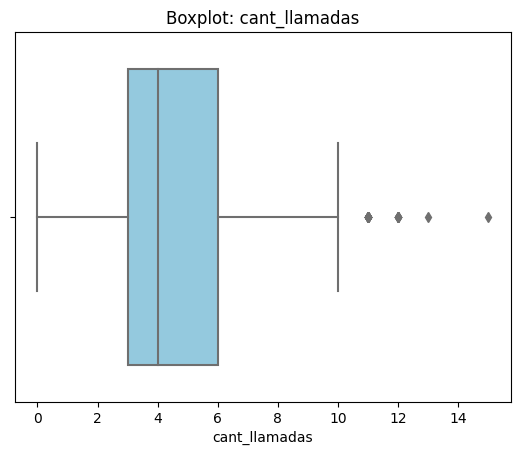

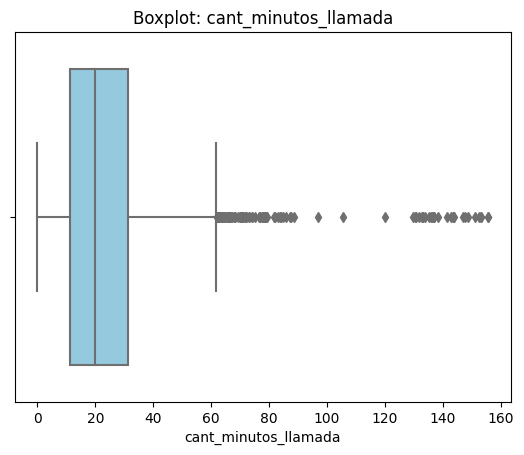

In [35]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: ...No presenta outliers. Distribución simétrica y uniforme entre 18 y 80 años, con mediana en 49 y un IQR amplio. La edad está bien distribuida sin valores atípicos, lo que confirma el muestreo balanceado que ya habíamos notado.
- cant_mensajes: ...Presenta outliers en la cola derecha . La caja es estrecha con mediana en 5 y IQR entre 4.5 y 7, lo que indica que la mayoría de usuarios envía pocos mensajes. Los outliers representan usuarios con actividad de mensajería muy por encima del promedio.
- cant_llamadas: ...Presenta outliers en la cola derecha. Comportamiento muy similar a cant_mensajes: caja compacta con mediana en 4 e IQR entre 3 y 6. La mayoría realiza pocas llamadas y un grupo reducido concentra una actividad inusualmente alta.
- cant_minutos_llamada: ...Es la variable con mayor presencia de outliers y la distribución más sesgada. La caja se concentra entre 0 y ~30 minutos con mediana en ~20, pero la cola se extiende hasta 160 minutos con dos clusters de outliers diferenciados: uno denso alrededor de 60–90 min y otro separado entre 130–160 min. Este segundo grupo es el rebrote anómalo que ya identificamos en el histograma y requiere investigación.

In [38]:
# Calcular límites con el método IQR
columnas_limites = [...]

columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

In [39]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 

- cant_mensajes: El máximo es 17 mensajes cuando el 75% de usuarios tiene 7 o menos. Sin embargo, 17 es un valor perfectamente alcanzable y realista en comportamiento de mensajería. No es un error de captura ni un valor imposible; simplemente representa usuarios más activos. Eliminarlos sesgaría el análisis de segmentación. Mantener outliers
- 
- cant_llamadas: Mismo razonamiento que cant_mensajes: el máximo es 15 llamadas con un IQR de 3–6. Un usuario que realiza 15 llamadas al mes es inusual pero válido. La std de 2.14 es baja, lo que confirma que los outliers son pocos y no distorsionan significativamente la media. Son usuarios reales con comportamiento diferenciado, útiles para segmentación. Mantener outliers
- 
- cant_minutos_llamada:  La media y la mediana están relativamente cerca, por lo que los outliers no están jalando excesivamente la distribución. Sin embargo, el máximo de 155.69 min es muy alejado del Q3 y corresponde al cluster anómalo de 130–160 min que ya identificamos. Se recomienda investigar ese subgrupo antes de decidir: si son registros válidos, se mantienen; si son errores de medición o un tipo de evento diferente, se separan o eliminan. Mantener outliers, pero tratar con precaucion.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [40]:
# Crear columna grupo_uso
def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [41]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [42]:
# Crear columna grupo_edad
def clasificar_edad(age):
    if age < 30:
        return 'Joven'
    elif age < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)

In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

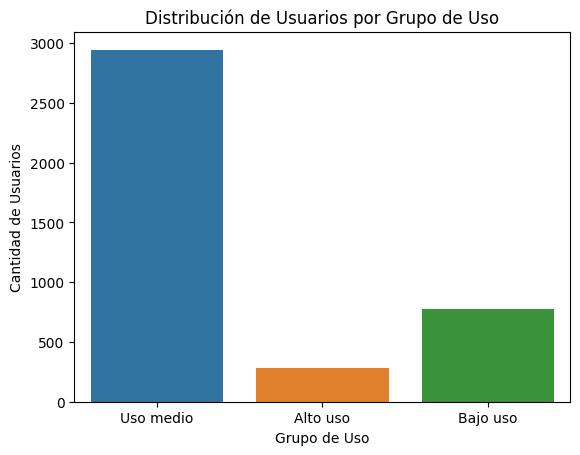

In [44]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')

plt.show()

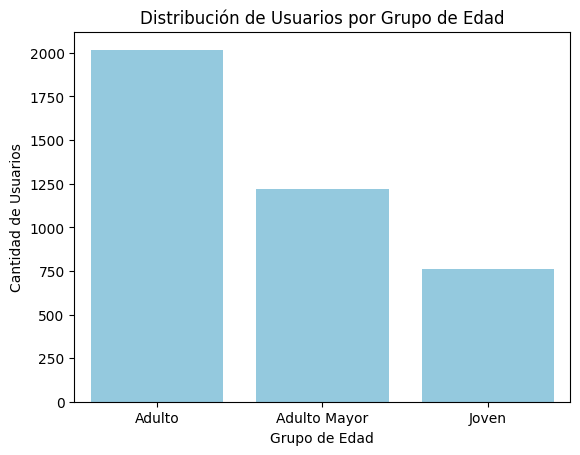

In [45]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', color='skyblue')
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**


Durante la exploración y limpieza se detectaron diversos problemas de calidad de datos:

city: 469 valores nulos (11.73% de los registros) y 96 registros con el valor inválido "?", equivalente al 2.4% de los usuarios. Se reemplazó "?" por valores nulos para su tratamiento adecuado.
age: Se identificó un valor sentinel de -999, claramente fuera del rango posible para una edad. Este valor fue reemplazado por la mediana para evitar distorsionar los análisis.
churn_date: Presentó 3,534 valores nulos (88.35%). Estos nulos son esperados porque la mayoría de los clientes no ha cancelado el servicio.
usage.date: Se encontraron 50 valores nulos (0.13%), una proporción muy baja que tiene impacto mínimo en el análisis.
duration: Contenía 22,076 valores nulos (55.19%).
length: Contenía 17,896 valores nulos (44.74%).

Se construyeron segmentos utilizando edad y nivel de uso.

Segmentación por edad
Segmentación por uso

Los resultados muestran que la mayoría de los clientes pertenece al segmento Adulto, mientras que los usuarios de alto uso representan una porción menor pero estratégicamente importante debido a su mayor consumo de servicios.

Los histogramas y boxplots mostraron valores extremos principalmente en:

Cantidad de mensajes.
Cantidad de llamadas.
Minutos totales de llamadas.

Estos outliers aparecen únicamente en la cola superior de las distribuciones, indicando la existencia de usuarios con consumos significativamente más altos que el promedio.

Existe un grupo reducido de clientes con consumo muy superior al promedio.
Estos usuarios pueden generar una proporción relevante de los ingresos.
Eliminarlos del análisis ocultaría oportunidades comerciales importantes.
Conviene monitorearlos y segmentarlos de forma independiente.

Recomendaciones:

1.- Crear planes con mayores beneficios en llamadas y mensajería para retener a los usuarios más activos y reducir el riesgo de migración a la competencia.

2.- Planes orientados a jóvenes con beneficios digitales y servicios de datos.

3.- Planes para adultos con paquetes balanceados de llamadas y mensajes.

4.- Planes para adultos mayores con enfoque en llamadas y simplicidad de uso.

5.- Identificar tempranamente a los usuarios de alto valor y ofrecer promociones, beneficios exclusivos o mejoras de plan para aumentar su permanencia.

6.- Implementar validaciones en los sistemas de captura para evitar valores sentinels, ciudades inválidas y fechas futuras que puedan afectar futuros análisis.


### 
Análisis ejecutivo

⚠️
 **Problemas detectados en los datos**
  city` tuvo 469 nulos (11.73%) y 96 registros con valor inválido "?" (2.4%),
  reemplazados por nulos. `age` contenía un valor sentinel de -999, sustituido
  por la mediana. `usage.date` presentó 50 nulos (0.13%) de impacto mínimo.
- `churn_date` tuvo 3,534 nulos (88.35%), esperados al ser clientes activos.
  `duration` y `length` concentraron los mayores vacíos: 55.19% y 44.74%
  respectivamente, limitando análisis de comportamiento detallado por sesión.



🔍 **Segmentos por Edad**
La mayoría de los clientes pertenece al segmento "Adulto" (30–59 años), seguido de "Adulto Mayor" (60+) y una proporción menor de "Jóvenes" (18–29). La distribución etaria es uniforme, sin concentración orgánica en ningún rango. - Se detectó un pico atípico de usuarios Básico en los 50 años, que no se replica en Premium, posiblemente originado por una campaña de adquisición puntual.


📊 **Segmentos por Nivel de Uso**
Los usuarios de "alto uso" (top en mensajes, llamadas y minutos)
  representan una porción menor del total, pero concentran un consumo
  significativamente superior al promedio, con outliers reales en las
  tres variables de actividad.
  
- La mayoría pertenece al segmento de "uso bajo-medio", con mediana
  de 5 mensajes, 4 llamadas y ~20 minutos por llamada. Los usuarios
  de alto uso permanecen mayoritariamente en plan Básico.



➡️ Esto sugiere que ...

Esto sugiere que el nivel de actividad no determina la adopción del
plan Premium: los usuarios más intensivos no están siendo convertidos,
lo que representa una oportunidad de monetización desaprovechada para
ConnectaTel.

💡 **Recomendaciones**
- Crear planes diferenciados por segmento: beneficios digitales para
  jóvenes, paquetes balanceados para adultos y simplicidad + llamadas
  para adultos mayores.
  
- Identificar y priorizar a los usuarios de alto uso con promociones
  exclusivas o upgrades de plan para aumentar conversión y retención
  antes de que migren a la competencia.
- Implementar validaciones en los sistemas de captura para prevenir
  valores sentinel, ciudades inválidas y nulos en campos críticos
  como `duration` y `length` que limitan análisis futuros.



---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`